# Round 1 Backtest Log Analysis

This notebook reads Prosperity backtest JSON outputs, parses the embedded `activitiesLog` and `graphLog`, and compares trials side by side.

It is designed to help answer questions like:
- when does a trial make or lose money
- how smooth is the PnL path
- what is happening in the ASH order book when the trial is active
- which trials look stable versus fragile

In [1]:
from io import StringIO
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Notebook parameters:
# - set TARGET_TRIAL to a trial folder name like "trial4"
# - set OUTPUT_STEM to control the exported file names
TARGET_TRIAL = "trial4"
OUTPUT_STEM = f"{TARGET_TRIAL}_backtest_log_report"
OUTPUT_DIR = None

def find_repo_root(start=None):
    start_path = Path(start or Path.cwd()).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "R1" / "trial1").exists():
            return candidate
    return start_path

ROOT = find_repo_root()
REPORT_DIR = Path(OUTPUT_DIR) if OUTPUT_DIR else (ROOT / "R1" / "erick" / "backtest_reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

trial_json_paths = sorted(ROOT.glob(f"R1/{TARGET_TRIAL}/*.json"))
if not trial_json_paths:
    trial_json_paths = sorted(ROOT.glob("R1/trial*/[0-9]*.json"))

trial_json_paths[:5], len(trial_json_paths), REPORT_DIR

([PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/trial4/123161.json')],
 1,
 PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports'))

In [2]:
def load_backtest_json(path):
    raw = json.loads(path.read_text())
    activities = pd.read_csv(StringIO(raw["activitiesLog"]), sep=";")
    graph = pd.read_csv(StringIO(raw["graphLog"]), sep=";")
    activities = activities.replace("", np.nan)
    graph = graph.replace("", np.nan)

    numeric_activity_cols = [
        "day",
        "timestamp",
        "bid_price_1",
        "bid_volume_1",
        "bid_price_2",
        "bid_volume_2",
        "bid_price_3",
        "bid_volume_3",
        "ask_price_1",
        "ask_volume_1",
        "ask_price_2",
        "ask_volume_2",
        "ask_price_3",
        "ask_volume_3",
        "mid_price",
        "profit_and_loss",
    ]
    for column in numeric_activity_cols:
        if column in activities.columns:
            activities[column] = pd.to_numeric(activities[column], errors="coerce")
    for column in ["timestamp", "value"]:
        if column in graph.columns:
            graph[column] = pd.to_numeric(graph[column], errors="coerce")

    trial_name = path.parent.name
    activities["trial"] = trial_name
    graph["trial"] = trial_name
    return raw, activities, graph


def ash_slice(activities):
    return activities[activities["product"] == "ASH_COATED_OSMIUM"].copy()


def max_drawdown(series):
    running_max = series.cummax()
    drawdown = running_max - series
    return float(drawdown.max())


def summarize_trial(path):
    raw, activities, graph = load_backtest_json(path)
    ash = ash_slice(activities).sort_values(["day", "timestamp"]).copy()
    ash = ash[ash["mid_price"].notna()].copy()
    ash = ash[(ash["mid_price"] > 0) & (ash["bid_price_1"] > 0) & (ash["ask_price_1"] > 0)].copy()
    ash["spread"] = ash["ask_price_1"] - ash["bid_price_1"]
    ash["top_depth"] = ash[["bid_volume_1", "ask_volume_1"]].min(axis=1)

    graph = graph.dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    pnl = graph["value"]
    if len(pnl) == 0:
        final_pnl = np.nan
        peak_pnl = np.nan
        valley_pnl = np.nan
        pnl_drawdown = np.nan
    else:
        final_pnl = float(pnl.iloc[-1])
        peak_pnl = float(pnl.max())
        valley_pnl = float(pnl.min())
        pnl_drawdown = max_drawdown(pnl)

    breakeven_ts = np.nan
    if len(graph) and (graph["value"] > 0).any():
        breakeven_ts = float(graph.loc[graph["value"] > 0, "timestamp"].iloc[0])

    return {
        "trial": path.parent.name,
        "path": str(path),
        "round": raw.get("round"),
        "status": raw.get("status"),
        "final_profit": float(raw.get("profit", np.nan)),
        "graph_final": final_pnl,
        "graph_peak": peak_pnl,
        "graph_valley": valley_pnl,
        "graph_drawdown": pnl_drawdown,
        "breakeven_timestamp": breakeven_ts,
        "ash_rows": int(len(ash)),
        "ash_days": int(ash["day"].nunique()) if len(ash) else 0,
        "ash_mid_first": float(ash["mid_price"].iloc[0]) if len(ash) else np.nan,
        "ash_mid_last": float(ash["mid_price"].iloc[-1]) if len(ash) else np.nan,
        "ash_spread_mean": float(ash["spread"].mean()) if len(ash) else np.nan,
        "ash_spread_median": float(ash["spread"].median()) if len(ash) else np.nan,
        "ash_top_depth_mean": float(ash["top_depth"].mean()) if len(ash) else np.nan,
    }

trial_data = []
for path in trial_json_paths:
    raw, activities, graph = load_backtest_json(path)
    trial_data.append({
        "meta": summarize_trial(path),
        "activities": activities,
        "graph": graph,
    })

summary_df = pd.DataFrame([item["meta"] for item in trial_data]).sort_values("final_profit", ascending=False)
summary_df

,trial,path,round,status,final_profit,graph_final,graph_peak,graph_valley,graph_drawdown,breakeven_timestamp,ash_rows,ash_days,ash_mid_first,ash_mid_last,ash_spread_mean,ash_spread_median,ash_top_depth_mean
0,trial4,/Users/ericlu/Works/imcp4/imcprosp4/R1/trial4/...,1,FINISHED,4927.9375,4924.125,4924.125,0.0,47.375,1200.0,914,1,10001.5,10003.0,16.253829,16.0,12.389497


In [ ]:
summary_df

In [3]:
report_csv_path = REPORT_DIR / f"{OUTPUT_STEM}.csv"
report_md_path = REPORT_DIR / f"{OUTPUT_STEM}.md"
summary_df.to_csv(report_csv_path, index=False)

selected_meta = summary_df.iloc[0].to_dict()
report_lines = [
    f"# Backtest Log Report: {selected_meta['trial']}",
    "",
    f"- Source: `{selected_meta['path']}`",
    f"- Round: {selected_meta['round']}",
    f"- Status: {selected_meta['status']}",
    f"- Final profit: {selected_meta['final_profit']:.2f}",
    f"- Graph final: {selected_meta['graph_final']:.2f}",
    f"- Graph drawdown: {selected_meta['graph_drawdown']:.2f}",
    f"- Breakeven timestamp: {selected_meta['breakeven_timestamp']}",
    "",
    "## Summary Table",
    "",
    summary_df.to_markdown(index=False),
]
report_md_path.write_text("\n".join(report_lines))

report_csv_path, report_md_path

(PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report.csv'),
 PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report.md'))

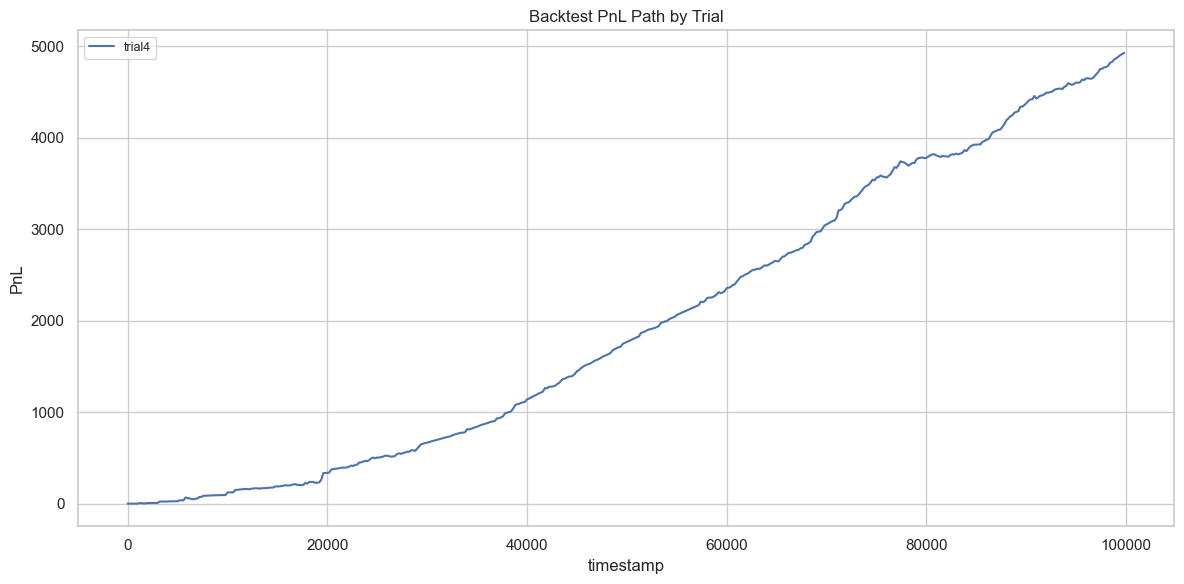

PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report_comparison.png')

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for item in trial_data:
    graph = item["graph"].dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    ax.plot(graph["timestamp"], graph["value"], label=item["meta"]["trial"])

ax.set_title("Backtest PnL Path by Trial")
ax.set_xlabel("timestamp")
ax.set_ylabel("PnL")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
comparison_plot_path = REPORT_DIR / f"{OUTPUT_STEM}_comparison.png"
fig.savefig(comparison_plot_path, dpi=150, bbox_inches="tight")
plt.show()
comparison_plot_path

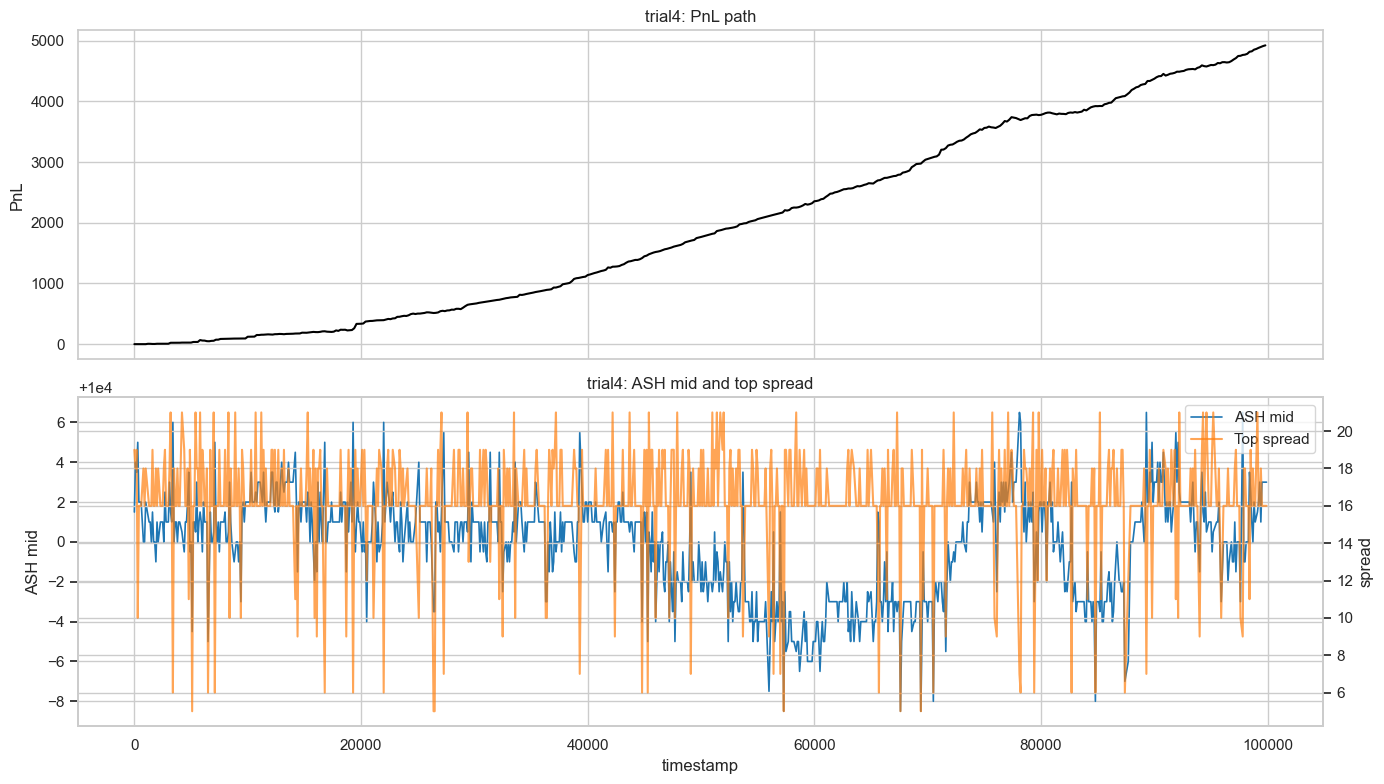

PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report_trial4.png')

In [5]:
def plot_trial(trial_name):
    match = next((item for item in trial_data if item["meta"]["trial"] == trial_name), None)
    if match is None:
        raise ValueError(f"Unknown trial: {trial_name}")

    activities = match["activities"].copy()
    graph = match["graph"].dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    ash = ash_slice(activities).sort_values(["day", "timestamp"]).copy()
    ash = ash[ash["mid_price"].notna()].copy()
    ash = ash[(ash["mid_price"] > 0) & (ash["bid_price_1"] > 0) & (ash["ask_price_1"] > 0)].copy()
    ash["spread"] = ash["ask_price_1"] - ash["bid_price_1"]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(graph["timestamp"], graph["value"], color="black", linewidth=1.5)
    axes[0].set_title(f"{trial_name}: PnL path")
    axes[0].set_ylabel("PnL")

    mid_line = axes[1].plot(ash["timestamp"], ash["mid_price"], label="ASH mid", color="tab:blue", linewidth=1.2)
    spread_ax = axes[1].twinx()
    spread_line = spread_ax.plot(ash["timestamp"], ash["spread"], label="Top spread", color="tab:orange", alpha=0.7)
    axes[1].set_title(f"{trial_name}: ASH mid and top spread")
    axes[1].set_xlabel("timestamp")
    axes[1].set_ylabel("ASH mid")
    spread_ax.set_ylabel("spread")

    lines = mid_line + spread_line
    labels = [line.get_label() for line in lines]
    axes[1].legend(lines, labels, loc="upper right")

    plt.tight_layout()
    detail_plot_path = REPORT_DIR / f"{OUTPUT_STEM}_{trial_name}.png"
    fig.savefig(detail_plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    return detail_plot_path

plot_trial(summary_df.iloc[0]["trial"])